install the required libraries

In [6]:
!pip install --upgrade pip
!pip install pykan
!pip install yfinance pandas numpy
!pip install pyarrow

Defaulting to user installation because normal site-packages is not writeable
  Using cached pip-26.3-py3-none-any.whl (2.0 MB)


ERROR: To modify pip, please run the following command:
C:\Program Files\Python311\python.exe -m pip install --upgrade pip

[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 29.0/29.0 MB 3.1 MB/s eta 0:00:00



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Download the S&P company list 

In [3]:
import pandas as pd
import requests
from io import StringIO

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Create a browser request
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120.0 Safari/537.36"
}

response = requests.get(url, headers=headers, timeout=30)

# Check whether the request worked
response.raise_for_status()

# Read the tables from Wikipedia
tables = pd.read_html(StringIO(response.text))

# Extract the first table
sp500 = tables[0]

# Display first 10 companies
display(sp500.head(10))

# Count companies
print("Number of companies:", len(sp500))

sp500.to_csv("sp500_company_list.csv", index=False)

print("Company list saved successfully!")

,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989
5,ADBE,Adobe Inc.,Information Technology,Application Software,"San Jose, California",1997-05-05,796343,1982
6,AMD,Advanced Micro Devices,Information Technology,Semiconductors,"Santa Clara, California",2017-03-20,2488,1969
7,AES,AES Corporation,Utilities,Independent Power Producers & Energy Traders,"Arlington, Virginia",1998-10-02,874761,1981
8,AFL,Aflac,Financials,Life & Health Insurance,"Columbus, Georgia",1999-05-28,4977,1955
9,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,"Santa Clara, California",2000-06-05,1090872,1999


Number of companies: 503
Company list saved successfully!


In [4]:
tickers = sp500["Symbol"].str.replace(".", "-", regex=False).tolist()

print("Number of tickers:", len(tickers))
print(tickers[:10])

Number of tickers: 503
['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


In [7]:
import yfinance as yf
import os
import time

# Create folder for downloaded data
os.makedirs("stock_data", exist_ok=True)

# Download in batches of 50
batch_size = 50

for i in range(0, len(tickers), batch_size):

    batch = tickers[i:i + batch_size]

    print("Downloading batch:", i // batch_size + 1)

    data = yf.download(
        tickers=batch,
        start="2021-01-01",
        end="2025-01-01",
        interval="1d",
        auto_adjust=False,
        actions=True,
        group_by="ticker",
        threads=True,
        progress=False
    )

    # Save each batch
    data.to_parquet(
        f"stock_data/batch_{i // batch_size + 1}.parquet"
    )

    time.sleep(2)

print("Download process finished!")

$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['FDXF']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['HONA']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['SNDK']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['VYLR']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Download process finished!


In [8]:
import yfinance as yf

failed_tickers = ["FDXF", "HONA", "Q", "SNDK", "VYLR"]

for ticker in failed_tickers:

    print("\nChecking:", ticker)

    data = yf.download(
        ticker,
        start="2021-01-01",
        end="2025-01-01",
        auto_adjust=False,
        progress=False
    )

    if data.empty:
        print("No historical data available.")
    else:
        print("Data available!")
        print("First date:", data.index.min())
        print("Last date:", data.index.max())
        print("Number of records:", len(data))


Checking: FDXF


$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['FDXF']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


No historical data available.

Checking: HONA


$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['HONA']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


No historical data available.

Checking: Q


$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


No historical data available.

Checking: SNDK


$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['SNDK']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['VYLR']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


No historical data available.

Checking: VYLR
No historical data available.


In [9]:
import pandas as pd

excluded = pd.DataFrame({
    "Ticker": ["FDXF", "HONA", "Q", "SNDK", "VYLR"],
    "Reason": [
        "No historical data available from Yahoo Finance",
        "No historical data available from Yahoo Finance",
        "No historical data available from Yahoo Finance",
        "No historical data available from Yahoo Finance",
        "No historical data available from Yahoo Finance"
    ]
})

excluded.to_csv("excluded_tickers.csv", index=False)
display(excluded)

,Ticker,Reason
0,FDXF,No historical data available from Yahoo Finance
1,HONA,No historical data available from Yahoo Finance
2,Q,No historical data available from Yahoo Finance
3,SNDK,No historical data available from Yahoo Finance
4,VYLR,No historical data available from Yahoo Finance


In [10]:
import glob
import os

files = glob.glob("stock_data/*.parquet")

print("Number of saved batch files:", len(files))

for file in files:
    print(os.path.basename(file),
          round(os.path.getsize(file) / 1024, 2), "KB")

Number of saved batch files: 11
batch_1.parquet 2181.75 KB
batch_10.parquet 2099.98 KB
batch_11.parquet 141.66 KB
batch_2.parquet 2188.85 KB
batch_3.parquet 2170.81 KB
batch_4.parquet 2124.45 KB
batch_5.parquet 2033.3 KB
batch_6.parquet 2159.18 KB
batch_7.parquet 2181.99 KB
batch_8.parquet 2083.82 KB
batch_9.parquet 2111.5 KB


In [11]:
import pandas as pd
import glob
import os

files = sorted(glob.glob("stock_data/*.parquet"))

# Open the first batch
sample = pd.read_parquet(files[0])

print("File inspected:", os.path.basename(files[0]))
print("\nData dimensions:")
print(sample.shape)

print("\nFirst five rows:")
display(sample.head())

print("\nColumn structure:")
print(sample.columns)

File inspected: batch_1.parquet

Data dimensions:
(1005, 400)

First five rows:


Ticker            ATO                                                       \
Price            Open       High        Low      Close  Adj Close   Volume   
Date                                                                         
2021-01-04  95.400002  95.919998  93.699997  94.029999  81.493210  1106700   
2021-01-05  94.269997  94.360001  92.000000  92.610001  80.262520   862000   
2021-01-06  93.070000  94.099998  92.480003  93.709999  81.215858   810200   
2021-01-07  93.720001  93.779999  89.389999  89.769997  77.801163   993900   
2021-01-08  90.000000  90.230003  88.330002  89.260002  77.359169  1054400   

Ticker                                   APO             ...       AIZ  \
Price      Dividends Stock Splits       Open       High  ... Dividends   
Date                                                     ...             
2021-01-04       0.0          0.0  48.980000  49.090000  ...       0.0   
2021-01-05       0.0          0.0  48.080002  48.759998  ...       0.0   
2021-01-06       0.0          0.0  47.939999  48.790001  ...       0.0   
2021-01-07       0.0          0.0  47.959999  48.080002  ...       0.0   
2021-01-08       0.0          0.0  47.500000  48.259998  ...       0.0   

Ticker                          ABT                                      \
Price      Stock Splits        Open        High         Low       Close   
Date                                                                      
2021-01-04          0.0  109.529999  110.250000  107.260002  109.110001   
2021-01-05          0.0  108.849998  110.910004  108.300003  110.459999   
2021-01-06          0.0  108.949997  111.029999  108.589996  110.230003   
2021-01-07          0.0  110.279999  111.620003  109.250000  111.300003   
2021-01-08          0.0  111.669998  112.550003  110.339996  111.610001   

Ticker                                                 
Price       Adj Close   Volume Dividends Stock Splits  
Date                                                   
2021-01-04  97.269699  6192000       0.0          0.0  
2021-01-05  98.473190  4322800       0.0          0.0  
2021-01-06  98.268158  5539600       0.0          0.0  
2021-01-07  99.222061  5568800       0.0          0.0  
2021-01-08  99.498390  4242200       0.0          0.0  

[5 rows x 400 columns]


Column structure:
MultiIndex([('ATO',         'Open'),
            ('ATO',         'High'),
            ('ATO',          'Low'),
            ('ATO',        'Close'),
            ('ATO',    'Adj Close'),
            ('ATO',       'Volume'),
            ('ATO',    'Dividends'),
            ('ATO', 'Stock Splits'),
            ('APO',         'Open'),
            ('APO',         'High'),
            ...
            ('AIZ',    'Dividends'),
            ('AIZ', 'Stock Splits'),
            ('ABT',         'Open'),
            ('ABT',         'High'),
            ('ABT',          'Low'),
            ('ABT',        'Close'),
            ('ABT',    'Adj Close'),
            ('ABT',       'Volume'),
            ('ABT',    'Dividends'),
            ('ABT', 'Stock Splits')],
           names=['Ticker', 'Price'], length=400)


Combine all 11 batches 

In [12]:
import pandas as pd
import glob
import os

# Find all batch files and sort them numerically
files = glob.glob("stock_data/batch_*.parquet")
files = sorted(files, key=lambda x: int(
    os.path.basename(x).replace("batch_", "").replace(".parquet", "")
))

# Read all batches
batch_data = []

for file in files:
    data = pd.read_parquet(file)
    batch_data.append(data)
    print(os.path.basename(file), data.shape)

# Combine all companies into one dataset
all_stocks = pd.concat(batch_data, axis=1)

# Sort dates
all_stocks = all_stocks.sort_index()

# Save the combined dataset
all_stocks.to_parquet("all_stocks_combined.parquet")

print("\nCombined dataset dimensions:", all_stocks.shape)
print("First date:", all_stocks.index.min())
print("Last date:", all_stocks.index.max())
print("Number of unique tickers:",
      all_stocks.columns.get_level_values("Ticker").nunique())

batch_1.parquet (1005, 400)
batch_2.parquet (1005, 400)
batch_3.parquet (1005, 400)
batch_4.parquet (1005, 398)
batch_5.parquet (1005, 398)
batch_6.parquet (1005, 400)
batch_7.parquet (1005, 400)
batch_8.parquet (1005, 398)
batch_9.parquet (1005, 398)
batch_10.parquet (1005, 398)
batch_11.parquet (1005, 24)

Combined dataset dimensions: (1005, 4014)
First date: 2021-01-04 00:00:00
Last date: 2024-12-31 00:00:00
Number of unique tickers: 503


# Check historical data coverage 

In [13]:
# Get all unique company tickers
tickers_in_data = all_stocks.columns.get_level_values("Ticker").unique()

coverage = []

for ticker in tickers_in_data:

    # Get this company's data
    company_data = all_stocks[ticker]

    # Count available closing prices and volume observations
    close_count = company_data["Close"].notna().sum()
    volume_count = company_data["Volume"].notna().sum()

    # Find first and last available closing-price dates
    valid_dates = company_data.index[company_data["Close"].notna()]

    first_date = valid_dates.min() if len(valid_dates) > 0 else None
    last_date = valid_dates.max() if len(valid_dates) > 0 else None

    coverage.append({
        "Ticker": ticker,
        "Close observations": close_count,
        "Volume observations": volume_count,
        "First available date": first_date,
        "Last available date": last_date
    })

coverage_df = pd.DataFrame(coverage)

# Show companies with the fewest closing-price observations
coverage_df = coverage_df.sort_values("Close observations")

display(coverage_df.head(20))

print("\nTotal companies:", len(coverage_df))
print("Companies with no closing prices:",
      (coverage_df["Close observations"] == 0).sum())

,Ticker,Close observations,Volume observations,First available date,Last available date
418,SNDK,0,0,NaT,NaT
382,Q,0,0,NaT,NaT
178,FDXF,0,0,NaT,NaT
211,HONA,0,0,NaT,NaT
495,VYLR,0,0,NaT,NaT
234,GEV,193,193,2024-03-27,2024-12-31
416,SOLV,194,194,2024-03-26,2024-12-31
359,RDDT,197,197,2024-03-21,2024-12-31
478,VLTO,313,313,2023-10-04,2024-12-31
207,GEHC,513,513,2022-12-15,2024-12-31



Total companies: 503
Companies with no closing prices: 5


# Identify Companies with full period data 

In [15]:
# Expected number of trading dates in the downloaded dataset
expected_days = len(all_stocks.index)

# Add a percentage coverage column
coverage_df["Coverage %"] = (
    coverage_df["Close observations"] / expected_days * 100
).round(2)

# Identify companies with data on every trading date
coverage_df["Full history"] = (
    coverage_df["Close observations"] == expected_days
)

# Summarise the results
print("Expected trading dates:", expected_days)

print("Companies with full history:",
      coverage_df["Full history"].sum())

print("Companies without full history:",
      (~coverage_df["Full history"]).sum())

print("\nCompanies with full history:")
display(
    coverage_df[coverage_df["Full history"]]
    .sort_values("Ticker")
)

print("\nCompanies without full history:")
display(
    coverage_df[~coverage_df["Full history"]]
    .sort_values("Close observations")
)

Expected trading dates: 1005
Companies with full history: 488
Companies without full history: 15

Companies with full history:


,Ticker,Close observations,Volume observations,First available date,Last available date,Coverage %,Full history
3,A,1005,1005,2021-01-04,2024-12-31,100.0,True
29,AAPL,1005,1005,2021-01-04,2024-12-31,100.0,True
11,ABBV,1005,1005,2021-01-04,2024-12-31,100.0,True
9,ABNB,1005,1005,2021-01-04,2024-12-31,100.0,True
49,ABT,1005,1005,2021-01-04,2024-12-31,100.0,True
...,...,...,...,...,...,...,...
51,XYZ,1005,1005,2021-01-04,2024-12-31,100.0,True
475,YUM,1005,1005,2021-01-04,2024-12-31,100.0,True
502,ZBH,1005,1005,2021-01-04,2024-12-31,100.0,True
500,ZBRA,1005,1005,2021-01-04,2024-12-31,100.0,True



Companies without full history:


,Ticker,Close observations,Volume observations,First available date,Last available date,Coverage %,Full history
418,SNDK,0,0,NaT,NaT,0.00,False
382,Q,0,0,NaT,NaT,0.00,False
178,FDXF,0,0,NaT,NaT,0.00,False
211,HONA,0,0,NaT,NaT,0.00,False
495,VYLR,0,0,NaT,NaT,0.00,False
234,GEV,193,193,2024-03-27,2024-12-31,19.20,False
416,SOLV,194,194,2024-03-26,2024-12-31,19.30,False
359,RDDT,197,197,2024-03-21,2024-12-31,19.60,False
478,VLTO,313,313,2023-10-04,2024-12-31,31.14,False
207,GEHC,513,513,2022-12-15,2024-12-31,51.04,False


In [16]:
coverage_df.to_csv("stock_data_coverage_report.csv", index=False)

print("Coverage report saved successfully.")

Coverage report saved successfully.


# Creating clean Dataset 

In [18]:
# Get the tickers with complete historical data
eligible_tickers = coverage_df.loc[
    coverage_df["Full history"], "Ticker"
].tolist()

# Keep only these companies in the combined dataset
clean_stocks = all_stocks.loc[
    :, all_stocks.columns.get_level_values("Ticker").isin(eligible_tickers)
].copy()

# Save the clean dataset
clean_stocks.to_parquet("clean_stocks_488.parquet")

# Save the list of included companies
pd.DataFrame({"Ticker": eligible_tickers}).to_csv(
    "included_tickers.csv", index=False
)

# Save the list of excluded companies
coverage_df.loc[
    ~coverage_df["Full history"]
].to_csv("excluded_tickers_full_report.csv", index=False)

print("Clean dataset dimensions:", clean_stocks.shape)
print("Number of included companies:",
      clean_stocks.columns.get_level_values("Ticker").nunique())
print("First date:", clean_stocks.index.min())
print("Last date:", clean_stocks.index.max())

Clean dataset dimensions: (1005, 3904)
Number of included companies: 488
First date: 2021-01-04 00:00:00
Last date: 2024-12-31 00:00:00


Download the S&P 500 benchmark

In [19]:
import yfinance as yf

benchmark = yf.download(
    "^GSPC",
    start="2021-01-01",
    end="2025-01-01",
    interval="1d",
    auto_adjust=False,
    actions=True,
    progress=False
)

print("Benchmark dimensions:", benchmark.shape)
print("First date:", benchmark.index.min())
print("Last date:", benchmark.index.max())

display(benchmark.head())
benchmark.to_parquet("sp500_benchmark.parquet")
print("Benchmark saved successfully.")
print(benchmark.columns)

Benchmark dimensions: (1005, 8)
First date: 2021-01-04 00:00:00
Last date: 2024-12-31 00:00:00


Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,,,
2021-01-04,3700.649902,3700.649902,0.0,3769.989990,3662.709961,3764.610107,0.0,5015000000
2021-01-05,3726.860107,3726.860107,0.0,3737.830078,3695.070068,3698.020020,0.0,4591020000
2021-01-06,3748.139893,3748.139893,0.0,3783.040039,3705.340088,3712.199951,0.0,6064110000
2021-01-07,3803.790039,3803.790039,0.0,3811.550049,3764.709961,3764.709961,0.0,5099160000
2021-01-08,3824.679932,3824.679932,0.0,3826.689941,3783.600098,3815.050049,0.0,4773040000


Benchmark saved successfully.
MultiIndex([(   'Adj Close', '^GSPC'),
            (       'Close', '^GSPC'),
            (   'Dividends', '^GSPC'),
            (        'High', '^GSPC'),
            (         'Low', '^GSPC'),
            (        'Open', '^GSPC'),
            ('Stock Splits', '^GSPC'),
            (      'Volume', '^GSPC')],
           names=['Price', 'Ticker'])


# Extract adjusted closing pricess 

In [20]:
# Extract adjusted closing prices for all 488 companies
stock_adj = clean_stocks.xs(
    "Adj Close",
    axis=1,
    level="Price"
)

# Extract adjusted closing price for the S&P 500
benchmark_adj = benchmark.xs(
    "Adj Close",
    axis=1,
    level="Price"
).iloc[:, 0]

print("Stock prices shape:", stock_adj.shape)
print("Benchmark prices shape:", benchmark_adj.shape)

display(stock_adj.head())
display(benchmark_adj.head())

#Convert daily prices into weekly prices
# Get the last available adjusted closing price in each Friday-ending week
weekly_stock_prices = stock_adj.resample("W-FRI").last()
weekly_benchmark_prices = benchmark_adj.resample("W-FRI").last()

print("Weekly stock prices:", weekly_stock_prices.shape)
print("Weekly benchmark prices:", weekly_benchmark_prices.shape)

display(weekly_stock_prices.head())
display(weekly_benchmark_prices.head())

# Calculate weekly percentage returns
weekly_stock_returns = weekly_stock_prices.pct_change()
weekly_benchmark_returns = weekly_benchmark_prices.pct_change()

# Remove the first week because it has no previous week for comparison
weekly_stock_returns = weekly_stock_returns.dropna()
weekly_benchmark_returns = weekly_benchmark_returns.dropna()

print("Weekly stock returns:", weekly_stock_returns.shape)
print("Weekly benchmark returns:", weekly_benchmark_returns.shape)

display(weekly_stock_returns.head())
display(weekly_benchmark_returns.head())

#Calculate mean weekly return and beta
# Create a results table
risk_return = pd.DataFrame(index=weekly_stock_returns.columns)


# Arithmetic mean of weekly returns
risk_return["Mean_Weekly_Return"] = (
    weekly_stock_returns.mean()
)

# Calculate beta for each company
market_variance = weekly_benchmark_returns.var()

for ticker in weekly_stock_returns.columns:

    covariance = weekly_stock_returns[ticker].cov(
        weekly_benchmark_returns
    )

    risk_return.loc[ticker, "Beta"] = (
        covariance / market_variance
    )

# Display results
risk_return.index.name = "Ticker"

print("Risk-return dataset dimensions:", risk_return.shape)

display(risk_return.head(10))

# Save results
risk_return.to_csv("risk_return_features.csv")
print("Risk-return features saved successfully.")

Stock prices shape: (1005, 488)
Benchmark prices shape: (1005,)


Ticker,ATO,APO,ARE,A,GOOGL,AFL,ACN,AMGN,ADI,ABNB,...,UPS,VRT,WFC,TWLO,VICI,WELL,V,ZBRA,ZTS,ZBH
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,81.493210,42.120152,133.016418,114.009117,85.492973,37.857132,232.029297,189.759628,132.622604,139.149994,...,125.353806,18.427361,25.887411,334.589996,18.036835,53.147114,208.365875,378.130005,152.951981,141.603348
2021-01-05,80.262520,42.446392,132.876251,114.941261,86.182426,37.918484,233.350296,190.680527,134.993164,148.300003,...,123.608932,18.059212,26.610867,341.239990,18.270979,53.457714,205.256073,380.570007,154.017883,144.053391
2021-01-06,81.215858,41.882076,127.158966,118.093239,85.332001,39.382282,235.901581,195.276749,135.601715,142.770004,...,123.241585,18.158707,28.493582,329.010010,18.314890,55.718197,203.447601,394.820007,156.280533,148.158401
2021-01-07,77.801163,41.353054,128.786880,121.235596,87.880760,39.163155,238.127304,195.921448,141.332794,151.270004,...,121.680420,18.178608,29.138590,357.149994,18.219759,54.613838,204.586258,409.100006,156.140289,147.280090
2021-01-08,77.359169,41.405952,129.230881,122.100471,89.044189,38.996624,238.995834,199.663696,142.359024,149.770004,...,121.213615,17.979609,28.929392,360.269989,18.783178,54.078915,206.155533,405.470001,157.178116,146.956451


Date
2021-01-04    3700.649902
2021-01-05    3726.860107
2021-01-06    3748.139893
2021-01-07    3803.790039
2021-01-08    3824.679932
Name: ^GSPC, dtype: float64

Weekly stock prices: (209, 488)
Weekly benchmark prices: (209,)


Ticker,ATO,APO,ARE,A,GOOGL,AFL,ACN,AMGN,ADI,ABNB,...,UPS,VRT,WFC,TWLO,VICI,WELL,V,ZBRA,ZTS,ZBH
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,77.359169,41.405952,129.230881,122.100471,89.044189,38.996624,238.995834,199.663696,142.359024,149.770004,...,121.213615,17.979609,28.929392,360.269989,18.783178,54.078915,206.155533,405.470001,157.178116,146.956451
2021-01-15,78.026520,42.278862,131.147018,121.283661,85.566780,40.740913,230.271240,205.524139,143.276398,169.270004,...,121.603867,19.412407,27.927027,388.649994,18.410004,55.433460,192.893448,409.220001,151.053986,148.038193
2021-01-22,77.211838,40.938633,131.513107,121.398964,93.736038,40.697071,231.288025,212.230072,141.305481,181.869995,...,121.672745,19.909908,27.804995,392.010010,19.310020,54.415386,193.304886,408.839996,152.945602,148.861023
2021-01-29,77.133835,40.506592,130.165588,115.479378,90.506783,39.601421,219.622375,202.125076,133.812393,183.630005,...,118.619278,20.019356,26.044306,359.429993,18.497810,52.284336,184.913208,387.829987,144.442947,142.074860
2021-02-05,77.177185,44.694798,133.740799,118.371910,103.457031,39.838070,230.171356,197.846985,135.111191,195.309998,...,125.797684,20.795452,28.470083,400.059998,19.719780,55.235031,199.763718,407.109985,149.153122,147.825531


Date
2021-01-08    3824.679932
2021-01-15    3768.250000
2021-01-22    3841.469971
2021-01-29    3714.239990
2021-02-05    3886.830078
Freq: W-FRI, Name: ^GSPC, dtype: float64

... (2 outputs left out)

Date
2021-01-15   -0.014754
2021-01-22    0.019431
2021-01-29   -0.033120
2021-02-05    0.046467
2021-02-12    0.012349
Freq: W-FRI, Name: ^GSPC, dtype: float64

Risk-return dataset dimensions: (488, 2)


,Mean_Weekly_Return,Beta
Ticker,,
ATO,0.003003,0.540770
APO,0.007663,1.358237
ARE,-0.001069,1.155529
A,0.001081,1.072944
GOOGL,0.004512,1.221132
AFL,0.004983,0.705866
ACN,0.002306,1.142431
AMGN,0.001551,0.475780
ADI,0.002497,1.132623


Risk-return features saved successfully.


# Run a quality check on risk return Dataset 

In [21]:
import numpy as np
import pandas as pd

print("Missing values:")
print(risk_return.isna().sum())

print("\nSummary statistics:")
display(risk_return.describe())

print("\nCompanies with missing values:")
display(risk_return[risk_return.isna().any(axis=1)])

# Get the latest 60 trading dates
latest_60_dates = clean_stocks.index[-60:]

# Identify the final observation date
observation_date = clean_stocks.index.max()

print("Observation date:", observation_date)
print("First date in latest 60 sessions:", latest_60_dates[0])
print("Last date in latest 60 sessions:", latest_60_dates[-1])
print("Number of sessions:", len(latest_60_dates))

rfm_results = []

for ticker in eligible_tickers:

    # Extract daily data for this company
    company = clean_stocks[ticker]

    close = company["Close"]
    volume = company["Volume"]

    # Average volume over the preceding 20 sessions
    previous_20_average = (
        volume.shift(1).rolling(window=20).mean()
    )

    # Identify unusually high-volume days
    high_volume_days = volume > (2 * previous_20_average)

    # RECENCY: latest qualifying high-volume date
    qualifying_dates = volume.index[high_volume_days.fillna(False)]

    if len(qualifying_dates) > 0:
        latest_high_volume_date = qualifying_dates.max()

        recency = (
            observation_date - latest_high_volume_date
        ).days
    else:
        recency = np.nan

    # FREQUENCY: number of qualifying days in latest 60 sessions
    frequency = high_volume_days.loc[latest_60_dates].sum()

    # MONETARY: sum of Close multiplied by Volume
    monetary = (
        close.loc[latest_60_dates] *
        volume.loc[latest_60_dates]
    ).sum()

    # Store results
    rfm_results.append({
        "Ticker": ticker,
        "Recency": recency,
        "Frequency": frequency,
        "Monetary": monetary
    })

# Create RFM dataset
rfm = pd.DataFrame(rfm_results).set_index("Ticker")

print("RFM dataset dimensions:", rfm.shape)
display(rfm.head(10))

rfm.to_csv("rfm_features.csv")
print("RFM dataset saved successfully.")

Missing values:
Mean_Weekly_Return    0
Beta                  0
dtype: int64

Summary statistics:


,Mean_Weekly_Return,Beta
count,488.000000,488.000000
mean,0.002801,0.972986
std,0.002623,0.406388
min,-0.004423,0.056026
25%,0.001138,0.667340
50%,0.002575,0.945883
75%,0.004170,1.176213
max,0.017462,3.778556



Companies with missing values:


,Mean_Weekly_Return,Beta
Ticker,,


Observation date: 2024-12-31 00:00:00
First date in latest 60 sessions: 2024-10-07 00:00:00
Last date in latest 60 sessions: 2024-12-31 00:00:00
Number of sessions: 60
RFM dataset dimensions: (488, 3)


,Recency,Frequency,Monetary
Ticker,,,
WFC,11,3,7.270194e+10
VRT,42,2,4.685913e+10
UPS,11,2,3.171983e+10
WRB,11,2,5.864965e+09
WST,11,5,1.224492e+10
VTR,11,3,9.773038e+09
WDAY,11,5,5.170406e+10
WM,11,4,1.961095e+10
VRSK,11,2,1.088500e+10


RFM dataset saved successfully.


Validate RFM results 

In [22]:
print("Missing values:")
print(rfm.isna().sum())

print("\nRFM summary statistics:")
display(rfm.describe())

print("\nNegative values:")
print((rfm < 0).sum())

print("\nCompanies with missing RFM values:")
display(rfm[rfm.isna().any(axis=1)])

print("\nFrequency range:")
print(rfm["Frequency"].min(), "to", rfm["Frequency"].max())

print("\nRecency range:")
print(rfm["Recency"].min(), "to", rfm["Recency"].max())

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

RFM summary statistics:


,Recency,Frequency,Monetary
count,488.000000,488.000000,4.880000e+02
mean,20.389344,2.987705,3.930290e+10
std,21.302843,1.328820,1.288833e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.023194e+10
50%,11.000000,3.000000,1.668382e+10
75%,15.000000,4.000000,3.210048e+10
max,222.000000,8.000000,1.847697e+12



Negative values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Companies with missing RFM values:


,Recency,Frequency,Monetary
Ticker,,,



Frequency range:
0 to 8

Recency range:
4 to 222


Prepare the Dataset for the clustering 

In [24]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# --------------------------------
# A. Prepare risk-return dataset
# --------------------------------

risk_return_clean = risk_return.copy()

risk_scaler = StandardScaler()

risk_scaled_array = risk_scaler.fit_transform(
    risk_return_clean
)

risk_scaled = pd.DataFrame(
    risk_scaled_array,
    index=risk_return_clean.index,
    columns=risk_return_clean.columns
)

# --------------------------------
# B. Prepare RFM dataset
# --------------------------------

rfm_clean = rfm.copy()

# Log transformation of Monetary
rfm_clean["Monetary_log"] = np.log1p(
    rfm_clean["Monetary"]
)

# Use Recency, Frequency and transformed Monetary
rfm_features = rfm_clean[
    ["Recency", "Frequency", "Monetary_log"]
]

# Standardise all three features
rfm_scaler = StandardScaler()

rfm_scaled_array = rfm_scaler.fit_transform(
    rfm_features
)

rfm_scaled = pd.DataFrame(
    rfm_scaled_array,
    index=rfm_features.index,
    columns=rfm_features.columns
)

print("Risk-return scaled shape:", risk_scaled.shape)
print("RFM scaled shape:", rfm_scaled.shape)

print("\nRisk-return scaled data:")
display(risk_scaled.head())

print("\nRFM scaled data:")
display(rfm_scaled.head())

risk_scaled.to_csv("risk_return_scaled.csv")
rfm_scaled.to_csv("rfm_scaled.csv")

print("Both scaled datasets saved successfully.")

Risk-return scaled shape: (488, 2)
RFM scaled shape: (488, 3)

Risk-return scaled data:


,Mean_Weekly_Return,Beta
Ticker,,
ATO,0.077240,-1.064647
APO,1.855395,0.948960
ARE,-1.476991,0.449643
A,-0.656267,0.246218
GOOGL,0.653050,0.611238



RFM scaled data:


,Recency,Frequency,Monetary_log
Ticker,,,
WFC,-0.441208,0.009262,1.414111
VRT,1.015490,-0.744058,0.946672
UPS,-0.441208,-0.744058,0.531400
WRB,-0.441208,-0.744058,-1.264985
WST,-0.441208,1.515901,-0.481581


Both scaled datasets saved successfully.


# Hierarchical clustering 
Risk return Dataset

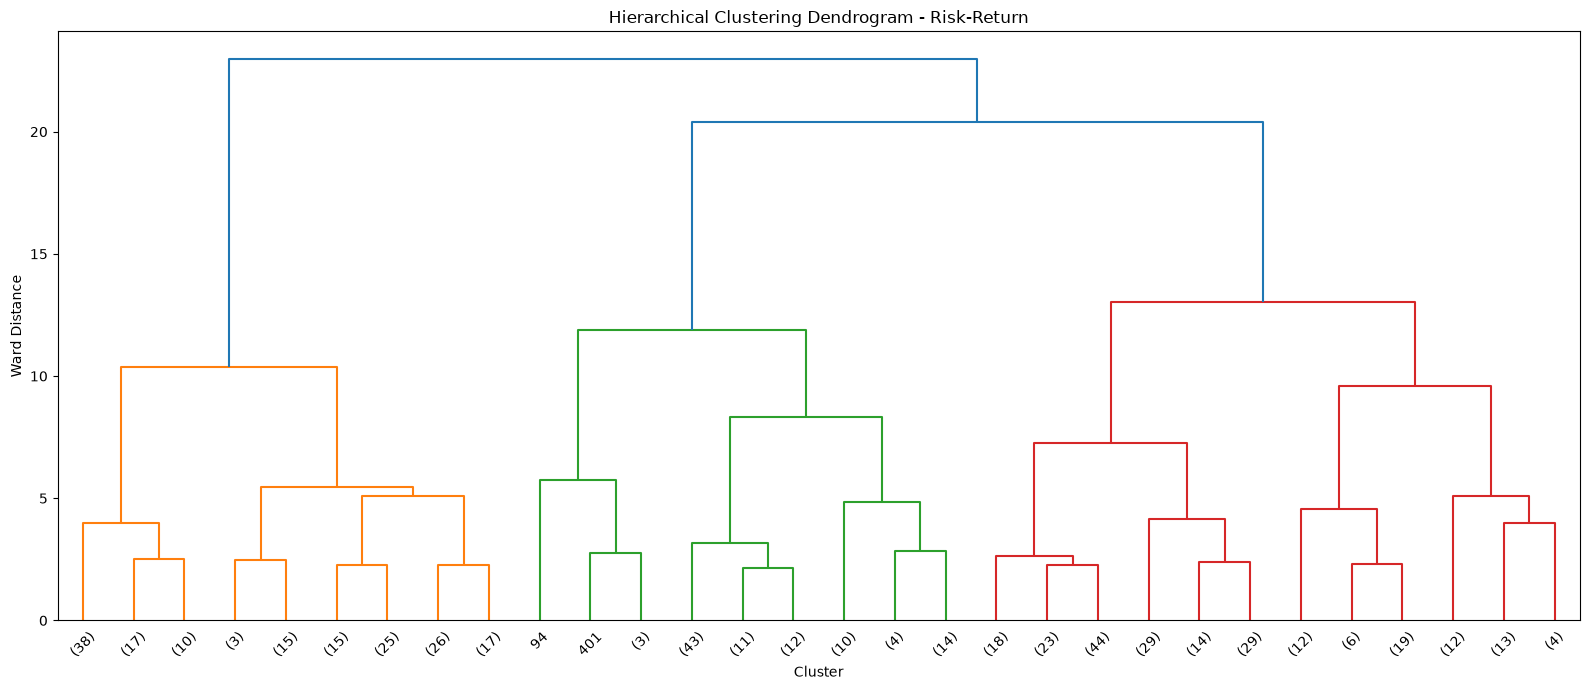

In [33]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

risk_linkage = linkage(
    risk_scaled,
    method="ward",
    metric="euclidean"
)

# Plot a readable dendrogram
plt.figure(figsize=(16, 7))

dendrogram(
    risk_linkage,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram - Risk-Return")
plt.xlabel("Cluster")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

RFM

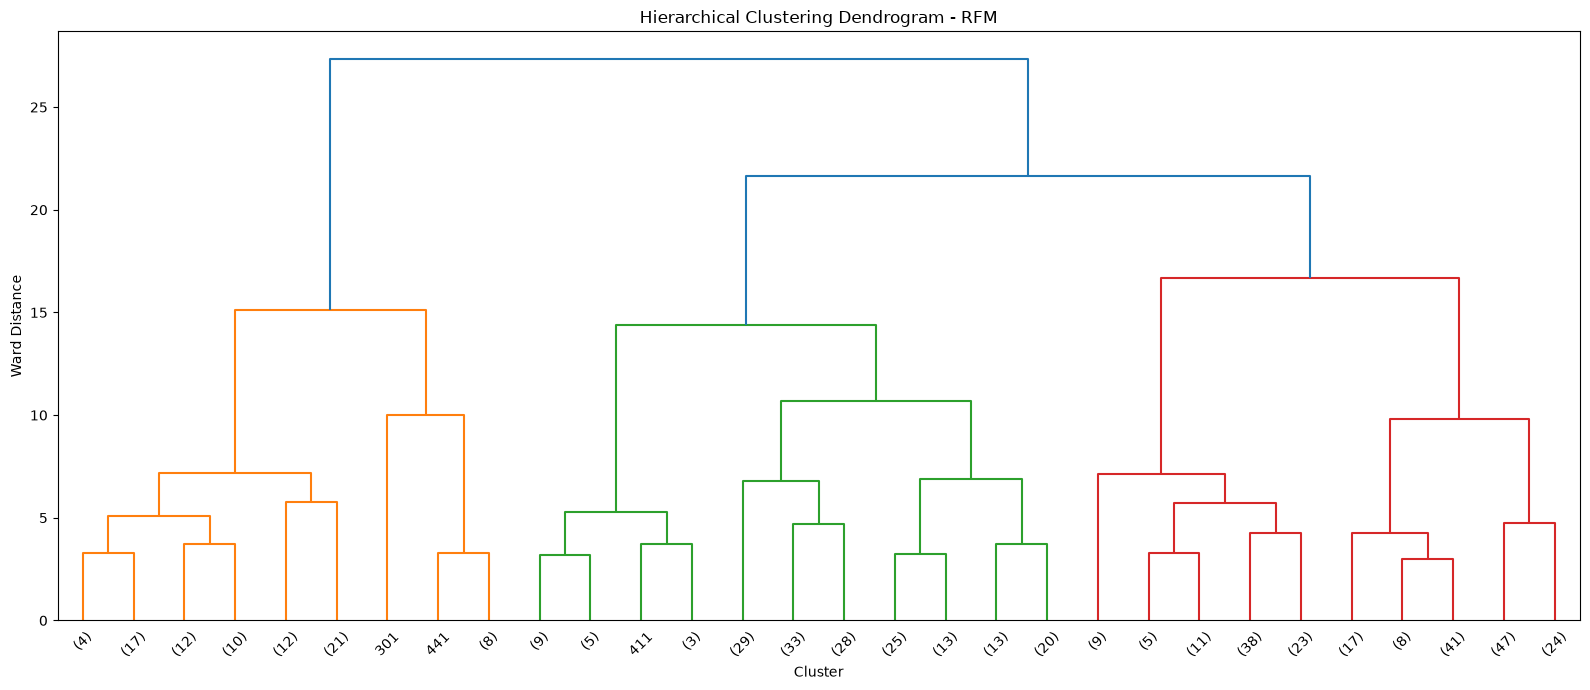

In [34]:
rfm_linkage = linkage(
    rfm_scaled,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(16, 7))

dendrogram(
    rfm_linkage,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram - RFM")
plt.xlabel("Cluster")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

Test different number of clusters 

In [35]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

risk_silhouette = []

for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(risk_scaled)

    score = silhouette_score(risk_scaled, labels)

    risk_silhouette.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": score
    })

risk_silhouette_df = pd.DataFrame(risk_silhouette)

display(risk_silhouette_df)

,Number_of_Clusters,Silhouette_Score
0,2,0.271696
1,3,0.304220
2,4,0.285210
3,5,0.298272
4,6,0.301917
5,7,0.313933
6,8,0.321995


In [36]:
rfm_silhouette = []

for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    rfm_silhouette.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": score
    })

rfm_silhouette_df = pd.DataFrame(rfm_silhouette)

display(rfm_silhouette_df)

,Number_of_Clusters,Silhouette_Score
0,2,0.369340
1,3,0.261434
2,4,0.251355
3,5,0.270088
4,6,0.291391
5,7,0.280443
6,8,0.281642


Save the hierarchical clustering results 

In [37]:
from sklearn.cluster import AgglomerativeClustering

# Final risk-return hierarchical clustering
risk_hierarchical = AgglomerativeClustering(
    n_clusters=8,
    linkage="ward"
)

risk_hierarchical_labels = risk_hierarchical.fit_predict(risk_scaled)

# Final RFM hierarchical clustering
rfm_hierarchical = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

rfm_hierarchical_labels = rfm_hierarchical.fit_predict(rfm_scaled)

# Store cluster labels
hierarchical_results = pd.DataFrame(index=risk_scaled.index)

hierarchical_results["Risk_Return_Cluster"] = risk_hierarchical_labels
hierarchical_results["RFM_Cluster"] = rfm_hierarchical_labels

display(hierarchical_results.head())

# Save results
hierarchical_results.to_csv("hierarchical_clustering_results.csv")

,Risk_Return_Cluster,RFM_Cluster
Ticker,,
ATO,5,0
APO,4,1
ARE,3,0
A,0,0
GOOGL,7,0


Examine the cluster sizes 

In [38]:
print("Risk-return cluster sizes:")
print(hierarchical_results["Risk_Return_Cluster"].value_counts().sort_index())

print("\nRFM cluster sizes:")
print(hierarchical_results["RFM_Cluster"].value_counts().sort_index())

Risk-return cluster sizes:
Risk_Return_Cluster
0    157
1      5
2    101
3     29
4     28
5     65
6     37
7     66
Name: count, dtype: int64

RFM cluster sizes:
RFM_Cluster
0    402
1     86
Name: count, dtype: int64


K-means for risk return 

In [39]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

risk_kmeans_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(risk_scaled)

    silhouette = silhouette_score(risk_scaled, labels)

    risk_kmeans_results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": silhouette,
        "Inertia": model.inertia_
    })

risk_kmeans_df = pd.DataFrame(risk_kmeans_results)

display(risk_kmeans_df)

,Number_of_Clusters,Silhouette_Score,Inertia
0,2,0.385367,627.205176
1,3,0.327148,465.186672
2,4,0.325648,375.041014
3,5,0.340701,311.910544
4,6,0.329223,266.929997
5,7,0.334296,228.505149
6,8,0.354569,196.554830


K-means for RFM

In [40]:
rfm_kmeans_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(rfm_scaled)

    silhouette = silhouette_score(rfm_scaled, labels)

    rfm_kmeans_results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": silhouette,
        "Inertia": model.inertia_
    })

rfm_kmeans_df = pd.DataFrame(rfm_kmeans_results)

display(rfm_kmeans_df)

,Number_of_Clusters,Silhouette_Score,Inertia
0,2,0.423769,1071.585297
1,3,0.325091,800.746441
2,4,0.341383,612.475070
3,5,0.357967,517.074772
4,6,0.345718,439.790631
5,7,0.347653,388.481919
6,8,0.344406,346.901989


Plot the K-means result 

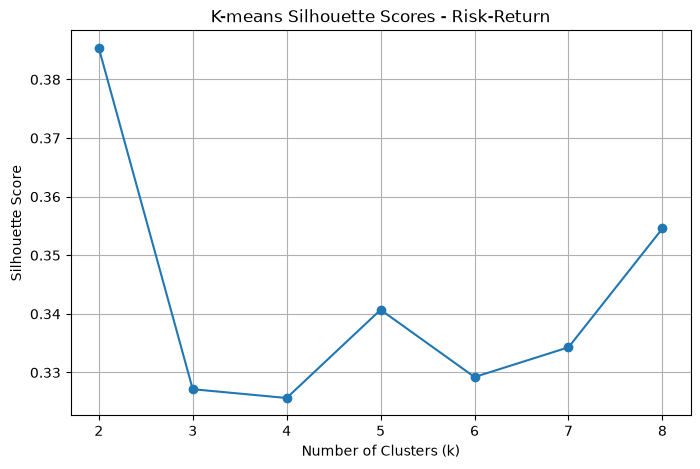

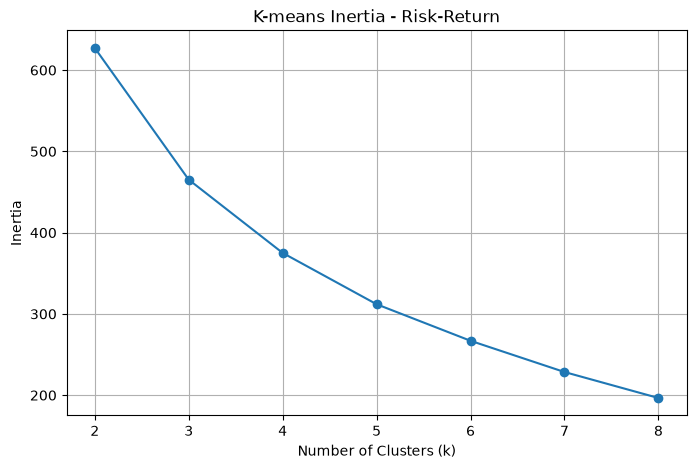

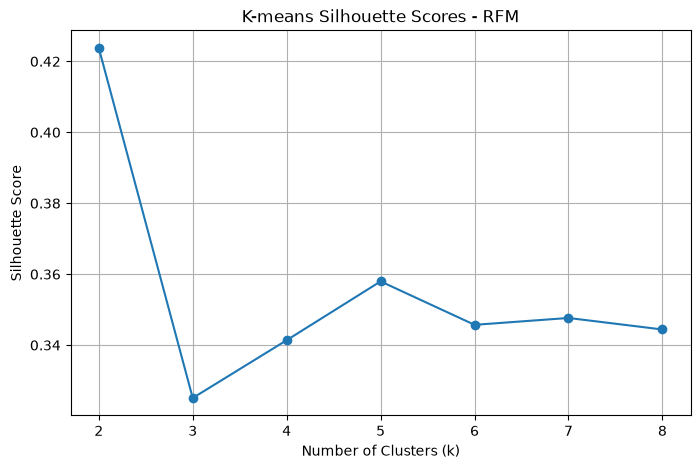

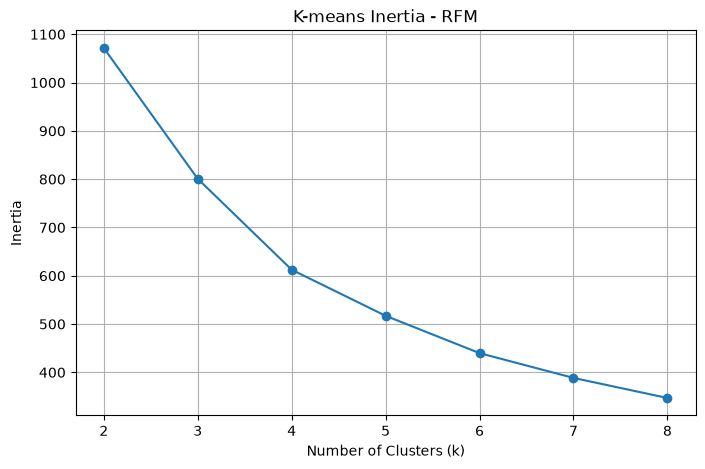

In [41]:
import matplotlib.pyplot as plt

# Risk-return silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(
    risk_kmeans_df["Number_of_Clusters"],
    risk_kmeans_df["Silhouette_Score"],
    marker="o"
)
plt.title("K-means Silhouette Scores - Risk-Return")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# Risk-return inertia
plt.figure(figsize=(8, 5))
plt.plot(
    risk_kmeans_df["Number_of_Clusters"],
    risk_kmeans_df["Inertia"],
    marker="o"
)
plt.title("K-means Inertia - Risk-Return")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# RFM silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(
    rfm_kmeans_df["Number_of_Clusters"],
    rfm_kmeans_df["Silhouette_Score"],
    marker="o"
)
plt.title("K-means Silhouette Scores - RFM")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# RFM inertia
plt.figure(figsize=(8, 5))
plt.plot(
    rfm_kmeans_df["Number_of_Clusters"],
    rfm_kmeans_df["Inertia"],
    marker="o"
)
plt.title("K-means Inertia - RFM")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# Save the results
risk_kmeans_df.to_csv("risk_return_kmeans_evaluation.csv", index=False)
rfm_kmeans_df.to_csv("rfm_kmeans_evaluation.csv", index=False)

In [42]:
from sklearn.cluster import KMeans
import pandas as pd

# Final risk-return K-means model
risk_kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

risk_kmeans_labels = risk_kmeans_final.fit_predict(risk_scaled)

# Final RFM K-means model
rfm_kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

rfm_kmeans_labels = rfm_kmeans_final.fit_predict(rfm_scaled)

# Combine all cluster assignments
final_results = pd.DataFrame(index=risk_scaled.index)

final_results["Risk_Return_Ward"] = risk_hierarchical_labels
final_results["Risk_Return_KMeans"] = risk_kmeans_labels
final_results["RFM_Ward"] = rfm_hierarchical_labels
final_results["RFM_KMeans"] = rfm_kmeans_labels

display(final_results.head(10))

# Save results
final_results.to_csv("final_clustering_results.csv")

,Risk_Return_Ward,Risk_Return_KMeans,RFM_Ward,RFM_KMeans
Ticker,,,,
ATO,5,1,0,0
APO,4,0,1,1
ARE,3,1,0,0
A,0,1,0,0
GOOGL,7,0,0,0
AFL,5,1,0,0
ACN,0,1,0,0
AMGN,2,1,0,0
ADI,0,1,0,0


In [43]:
print("Risk-return K-means cluster sizes:")
print(final_results["Risk_Return_KMeans"].value_counts().sort_index())

print("\nRFM K-means cluster sizes:")
print(final_results["RFM_KMeans"].value_counts().sort_index())

Risk-return K-means cluster sizes:
Risk_Return_KMeans
0    143
1    345
Name: count, dtype: int64

RFM K-means cluster sizes:
RFM_KMeans
0    420
1     68
Name: count, dtype: int64


In [44]:
# Risk-return cluster profiles
risk_profile = risk_return.join(
    final_results["Risk_Return_KMeans"]
).groupby("Risk_Return_KMeans").agg(
    Company_Count=("Mean_Weekly_Return", "count"),
    Average_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Average_Beta=("Beta", "mean")
)

print("Risk-return K-means profiles:")
display(risk_profile.round(4))


# RFM cluster profiles
rfm_profile = rfm.join(
    final_results["RFM_KMeans"]
).groupby("RFM_KMeans").agg(
    Company_Count=("Recency", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
)

print("RFM K-means profiles:")
display(rfm_profile.round(2))

Risk-return K-means profiles:


,Company_Count,Average_Weekly_Return,Average_Beta
Risk_Return_KMeans,,,
0,143,0.0052,1.3499
1,345,0.0018,0.8168


RFM K-means profiles:


,Company_Count,Average_Recency,Average_Frequency,Average_Monetary
RFM_KMeans,,,,
0,420,19.90,2.97,4.078994e+10
1,68,23.44,3.10,3.011825e+10


Examine the hierarchical cluster profile 

In [45]:
# Risk-return Ward cluster profiles
risk_ward_profile = risk_return.join(
    final_results["Risk_Return_Ward"]
).groupby("Risk_Return_Ward").agg(
    Company_Count=("Mean_Weekly_Return", "count"),
    Average_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Average_Beta=("Beta", "mean")
)

print("Risk-return Ward profiles:")
display(risk_ward_profile.round(4))


# RFM Ward cluster profiles
rfm_ward_profile = rfm.join(
    final_results["RFM_Ward"]
).groupby("RFM_Ward").agg(
    Company_Count=("Recency", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
)

print("RFM Ward profiles:")
display(rfm_ward_profile.round(2))

Risk-return Ward profiles:


,Company_Count,Average_Weekly_Return,Average_Beta
Risk_Return_Ward,,,
0,157,0.0018,0.9948
1,5,0.0127,2.3399
2,101,0.0011,0.5396
3,29,-0.0011,1.4910
4,28,0.0081,1.3197
5,65,0.0042,0.6015
6,37,0.0033,1.5782
7,66,0.0049,1.1326


RFM Ward profiles:


,Company_Count,Average_Recency,Average_Frequency,Average_Monetary
RFM_Ward,,,,
0,402,20.07,2.96,4.085956e+10
1,86,21.87,3.12,3.202639e+10


RFM sensitivity analysist - remove monetary 

In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

# Step 1: Keep Recency and Frequency only
rf_only = rfm[["Recency", "Frequency"]].copy()

# Step 2: Standardise the two remaining features
rf_scaler = StandardScaler()
rf_scaled = pd.DataFrame(
    rf_scaler.fit_transform(rf_only),
    index=rf_only.index,
    columns=rf_only.columns
)

# Step 3: Repeat Ward clustering with 2 clusters
rf_ward_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

rf_ward_labels = rf_ward_model.fit_predict(rf_scaled)

# Step 4: Compare with original RFM Ward labels
ari_score = adjusted_rand_score(
    rfm_hierarchical_labels,
    rf_ward_labels
)

print("Adjusted Rand Index:", round(ari_score, 4))

# Step 5: Check revised cluster sizes
print("\nCluster sizes without Monetary:")
print(pd.Series(rf_ward_labels).value_counts().sort_index())

Adjusted Rand Index: 0.9225

Cluster sizes without Monetary:
0    398
1     90
Name: count, dtype: int64


Examine correlations between RFM features 

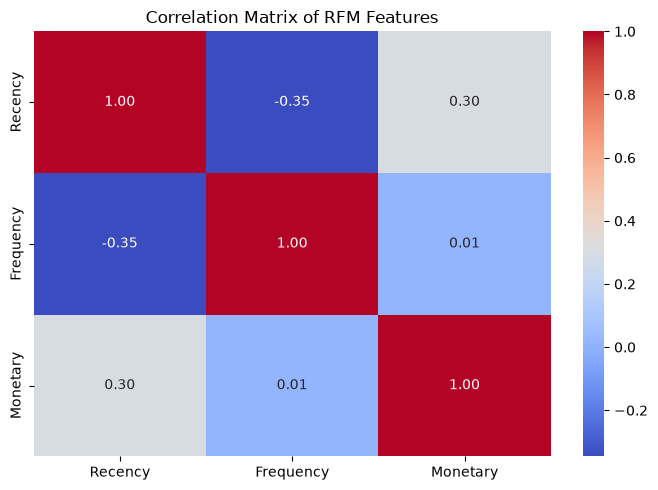

,Recency,Frequency,Monetary
Recency,1.000,-0.346,0.300
Frequency,-0.346,1.000,0.014
Monetary,0.300,0.014,1.000


In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

rfm_correlations = rfm[["Recency", "Frequency", "Monetary"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    rfm_correlations,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of RFM Features")
plt.tight_layout()
plt.show()

display(rfm_correlations.round(3))